# Übung 01: Einführung in Python und Jupyter Notebooks

In dieser Übung arbeiten wir mit Python in einem Jupyter Notebook. Ein Notebook verbindet erklärenden Text, ausführbaren Code und die zugehörigen Ausgaben in einer Datei mit der Endung `.ipynb`. Wir betrachten heute einen bereits vorhandenen medizinischen Datensatz und beschreiben zunächst einzelne Spalten.

**Aufgabe 1 ist eine vollständig ausgearbeitete Vorführung.** Hier werden alle Schritte und Ergebnisse gemeinsam besprochen; es gibt keine Lücken und keine eigenen Antworten zu ergänzen. In **Aufgabe 2** überträgst du denselben Ablauf auf ein anderes Merkmal. Eigene Programmierstellen erkennst du an `# Hier dein Code`. Schriftliche Antworten gehören in die leere Textzelle unter „Ihre Lösung:“. In dieser Einführung gibt es ausnahmsweise noch keine Klausuraufgabe.

Für die Bearbeitung werden dieses Notebook und die in Moodle verfügbare Datei `diabetes.csv` benötigt. Die Musterlösung enthält dieselben Erklärungen und Aufgaben sowie die ergänzten Code- und Textantworten.

### Das Notebook öffnen und bedienen

**Google Colab:** Öffne das Notebook über Moodle den Moodle-Link, beziehungsweise lade die `.ipynb`-Datei in [Colab](https://colab.research.google.com/) hoch. Melde dich mit deinem Google-Konto an und speichere über **Datei → Kopie in Drive speichern** eine eigene Kopie. Du kannst sie später aus Drive oder über die zuletzt geöffneten Notebooks in Colab wieder öffnen.
In Moodle findet ihr auch ein kurzes Video und ein schriftliches Tutorial.

**Lokal:** Öffne das Notebook in Jupyter Notebook oder JupyterLab in einer Python-Umgebung mit NumPy, pandas und Matplotlib. Lege `diabetes.csv` neben das Notebook und starte Jupyter in diesem Ordner. Eine eigene Python-IDE, beispielsweise Spyder, ist ebenfalls möglich; dort überträgst du die Codeabschnitte in ein Skript.

Eine **Codezelle** enthält Python-Befehle. **Shift+Enter** führt sie aus und springt zur nächsten Zelle. In Colab kannst du auch den "Play-Button" links an der Codezelle verwenden; bei der ersten Ausführung wird die Laufzeit verbunden (das kann kurz dauern; der Laufzeit-Status ist oben rechts sichtbar). Eine laufende Zelle lässt sich über den Stop-Button abbrechen. Eine **Textzelle** enthält Erklärungen oder deine schriftlichen Antworten und kann per Doppelklick bearbeitet werden.

Führe Codezellen von oben nach unten aus. Variablen und importierte Bibliotheken bleiben über Zellgrenzen hinweg in der Laufzeit verfügbar. Änderst du eine frühe Zelle, müssen die davon abhängigen Zellen erneut laufen. Nach einem Neustart der Laufzeit sind die Variablen weg. Bereits gespeicherte Ausgaben bleiben trotzdem sichtbar.

## Aufgabe 1: Alterswerte untersuchen – Vorführübung

Wir möchten wissen, wie alt die Personen im Datensatz im Mittel sind und welcher Anteil mindestens 40 Jahre alt ist. Zunächst wollen wir allerdings ein Gefühl für Datentypen und allgemeine Programmierlogik in Python bekommen. Dazu betrachten wir zuerst fünf Werte von Hand und automatisieren die Rechnung anschließend.

### a) Variablen, Datentypen und Listen

Mit `=` weisen wir einer Variablen einen Wert zu. Python unterscheidet beispielsweise ganze Zahlen (`int`), Dezimalzahlen (`float`), Text (`str`) und Wahrheitswerte (`bool`). Dezimalzahlen werden im Code mit einem Punkt geschrieben; Text steht in Anführungszeichen. `print(...)` zeigt Werte an, `type(...)` ihren Datentyp.

In [2]:
age = 50
mean_example = 33.4
feature_name = "Age"
is_at_least_40 = age >= 40

print(age, type(age))
print(mean_example, type(mean_example))
print(feature_name, type(feature_name))
print(is_at_least_40, type(is_at_least_40))

50 <class 'int'>
33.4 <class 'float'>
Age <class 'str'>
True <class 'bool'>


Eine **Liste** fasst mehrere Werte zusammen. Wir verwenden die ersten fünf Alterswerte des Datensatzes: `[50, 31, 32, 21, 33]`. Eckige Klammern erzeugen die Liste und wählen einzelne Einträge aus. Python zählt Positionen ab **0**: `ages_small[0]` ist also der erste Wert, `ages_small[1]` der zweite. `len(...)` liefert die Anzahl der Einträge und `sum(...)` ihre Summe.

Für den Mittelwert teilen wir die Summe durch die Anzahl. Klammern mit `(...)` rufen eine Funktion auf, eckige Klammern mit `[...]` greifen hier auf Listeneinträge zu. Ein Kommentar beginnt mit `#`; Python führt diesen Text nicht aus.

In [3]:
ages_small = [50, 31, 32, 21, 33]
print("Erster Alterswert:", ages_small[0])
print("Anzahl der Werte:", len(ages_small))
print("Mittelwert:", sum(ages_small) / len(ages_small), "Jahre")
# Diese Zeile wird nicht ausgeführt, sondern dient rein der Dokumentation

Erster Alterswert: 50
Anzahl der Werte: 5
Mittelwert: 33.4 Jahre


Mit einer `for`-Schleife bearbeiten wir nacheinander jeden Wert. Eine `if`-Bedingung entscheidet, ob ein eingerückter Abschnitt ausgeführt wird. Nach der Schleifenzeile und der Bedingung steht jeweils ein Doppelpunkt. Die **Einrückung** legt fest, welche Zeilen dazugehören; üblich sind vier Leerzeichen je Ebene.

Der Zähler beginnt bei null. Bei jedem Wert ab 40 erhöhen wir ihn um eins. `>=` bedeutet „größer oder gleich“. `==` würde zwei Werte auf Gleichheit prüfen; das einfache `=` ist eine Zuweisung. Der Prozentwert ergibt sich aus `100 * Anzahl / Gesamtzahl`.

In [4]:
count = 0
for value in ages_small:
    if value >= 40:
        count = count + 1

percentage = 100 * count / len(ages_small)
print("Anzahl ab 40 Jahren:", count)
print("Anteil ab 40 Jahren:", percentage, "%")

Anzahl ab 40 Jahren: 1
Anteil ab 40 Jahren: 20.0 %


Von den fünf Werten erfüllt nur `50` die Bedingung. Damit erhalten wir `1 / 5 = 0.2` als Anteil beziehungsweise **20 %**. Der Mittelwert der fünf Alterswerte beträgt **33,4 Jahre**.

### b) Bibliotheken importieren und verwenden

Viele Funktionen für Datenanalyse stehen in **Bibliotheken** bereit. Eine Bibliothek muss in der verwendeten Python-Umgebung installiert sein. `import` macht sie anschließend in der aktuellen Laufzeit verfügbar. Das sind zwei verschiedene Schritte. In Colab sind NumPy, pandas und Matplotlib üblicherweise bereits vorhanden; für diese Übung ist dort normalerweise keine zusätzliche Installation nötig. Für eine Anleitung zur Installation in einer lokalen Umgebung, könnt ihr das Tutorial anschauen.

Wir importieren **NumPy** für numerische Rechnungen, **pandas** für Tabellen und **Matplotlib** für Diagramme. Mit `as` vergeben wir die üblichen Kurzformen `np`, `pd` und `plt`. Der Punkt in `np.mean(...)` bedeutet, dass Python die Funktion `mean` in NumPy sucht. Das Importieren von NumPy legt keinen einzelnen Namen `mean` an.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Mittelwert mit NumPy:", np.mean(ages_small), "Jahre")

Mittelwert mit NumPy: 33.4 Jahre


### c) Dokumentation lesen

Bei unbekannten Funktionen hilft die Dokumentation. `help(np.mean)` zeigt die Hilfe zur Funktion an. Dabei übergeben wir die **Funktion selbst**, ohne sie mit weiteren Klammern aufzurufen. `help(np.mean(ages_small))` würde dagegen zuerst einen Mittelwert berechnen und dann Hilfe zu diesem Ergebnis anzeigen.

Die [Dokumentation zu `numpy.mean`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) ist folgendermaßen aufgebaut:

- Die **Signatur** zeigt den Funktionsnamen und die Parameter. Parameter mit einem bereits angegebenen Wert sind optional.
- Unter **Parameters** steht bei `a`, welche Daten die Funktion erwartet. Unsere Liste kann als solche Eingabe verwendet werden. `axis=None` ist der Standard; bei unserer eindimensionalen Liste werden alle Einträge berücksichtigt.
- **Returns** beschreibt das Ergebnis. Hier erhalten wir einen einzelnen Mittelwert.
- **Examples** enthält kleine Aufrufe zum Nachvollziehen. Sie helfen dabei, das Verhalten zuerst an wenigen bekannten Zahlen zu prüfen.

Für unsere Liste genügt `np.mean(ages_small)`. Wir müssen nicht alle optionalen Parameter setzen. Die folgende Hilfe darf nach dem Lesen wieder zugeklappt werden.

In [6]:
help(np.mean)

Help on method descriptor mean in module numpy:

mean(
    a,
    axis=None,
    dtype=None,
    out=None,
    keepdims=<no value>,
    *,
    where=<no value>
)
    Compute the arithmetic mean along the specified axis.

    Returns the average of the array elements.  The average is taken over
    the flattened array by default, otherwise over the specified axis.
    `float64` intermediate and return values are used for integer inputs.

    Parameters
    ----------
    a : array_like
        Array containing numbers whose mean is desired. If `a` is not an
        array, a conversion is attempted.
    axis : None or int or tuple of ints, optional
        Axis or axes along which the means are computed. The default is to
        compute the mean of the flattened array.

        If this is a tuple of ints, a mean is performed over multiple axes,
        instead of a single axis or all the axes as before.
    dtype : data-type, optional
        Type to use in computing the mean.  For inte

### d) Eine CSV-Datei laden und ihre Spalten auswählen

Jetzt verwenden wir tatsächlich die Datei `diabetes.csv`. Sie enthält **768 Zeilen und 9 Spalten**. Eine Zeile beschreibt eine Person; die Spalten enthalten Merkmale und eine Zielvariable. Die Daten entstammen der [Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database). Wir verwenden hier nur die Spalten `Age` (Alter in Jahren) und später `Pregnancies` (dokumentierte Anzahl der Schwangerschaften).

CSV bedeutet *Comma-Separated Values*: In unserer Datei trennt ein Komma die Spalten, die erste Zeile enthält ihre Namen. `pd.read_csv(...)` liest die Datei als **DataFrame**, also als Tabelle mit Zeilen- und Spaltenbezeichnungen, ein. Die Dateiendung allein garantiert jedoch kein bestimmtes Trennzeichen; die Dokumentation erläutert dafür beispielsweise den Parameter `sep`.

In [7]:
# Wenn ihr eure Daten in Google Drive hochgeladen habt (empfohlen - eventuell Ordner noch anpassen; MyDrive heißt in der deutschen Drive-Version "Meine Ablage"):
#from google.colab import drive
#drive.mount("/content/drive")
df = pd.read_csv("C:\\Users\\steve\\Desktop\\Master\\Semester_2\\KI_in_Med\\Übungen\\KI-in-der-Medizin\\src\\Daten\\diabetes.csv")
# Wenn ihr die Daten in der aktuellen Laufzeitumgebung hochladet:
# df = pd.read_csv("diabetes.csv")

print("Zeilen und Spalten:", df.shape)
print("Spaltennamen:", list(df.columns))
df.head()

Zeilen und Spalten: (768, 9)
Spaltennamen: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


`df.shape` liefert das Zahlenpaar `(768, 9)`. `df.columns` enthält die Spaltennamen und `df.head()` zeigt standardmäßig die ersten fünf Zeilen. `head` ist eine **Methode**, also eine Funktion, die zum Objekt `df` gehört. `shape` und `columns` sind dagegen **Attribute** und werden ohne Aufrufklammern gelesen.

`df["Age"]` wählt eine Spalte anhand ihres Namens aus. Das Ergebnis ist eine **Series**, eine beschriftete Folge von Werten. Mit `.to_numpy()` erhalten wir die Zahlen als eindimensionales NumPy-Array. Für dessen Positionen gilt wie bei unserer Liste die Zählung ab null. `ages[:5]` ist ein Ausschnitt (*Slice*): Er enthält die Positionen 0 bis 4, die rechte Grenze gehört nicht mehr dazu. Ein Array kann im Gegensatz zu einer Python-Liste auch direkt elementweise rechnen, beispielsweise `ages + 1`.

In [8]:
ages = df["Age"].to_numpy()
print("Erste fünf Alterswerte:", ages[:5])
print("Anzahl:", len(ages))
print("Mittelwert:", round(float(np.mean(ages)), 2), "Jahre")

Erste fünf Alterswerte: [50 31 32 21 33]
Anzahl: 768
Mittelwert: 33.24 Jahre


`float(...)` wandelt den NumPy-Wert in eine Python-Dezimalzahl um. `round(..., 2)` rundet hier nur die angezeigte Zahl auf zwei Nachkommastellen. Die Reihenfolge verschachtelter Aufrufe geht von innen nach außen: erst den Mittelwert berechnen, dann umwandeln und runden, zuletzt ausgeben. Für alle 768 Personen erhalten wir **33,24 Jahre**.

### e) Eine Funktion schreiben und dokumentieren

Eine Funktion fasst einen wiederverwendbaren Rechenweg zusammen. `def percentage_at_least(values, threshold):` legt den Namen und zwei **Parameter** fest: die Werte und die Grenze. Beim Aufruf `percentage_at_least(ages, 40)` werden die konkreten **Argumente** `ages` und `40` übergeben. Die Bezeichnungen im Funktionsinneren heißen weiterhin `values` und `threshold`. Die eingerückten Zeilen bilden den Funktionskörper. `return` gibt das Ergebnis an die aufrufende Stelle zurück; `print` würde es nur anzeigen.

Direkt am Anfang steht eine Zeichenkette in drei Anführungszeichen: der **Docstring**. Er beschreibt Zweck, Eingaben und Ausgabe und wird von `help(...)` angezeigt. Die Funktionsdokumentation und die Kommentare innerhalb von Funktionen schreiben wir wie in den weiteren Übungen auf Englisch. Für jeden Parameter nennen wir Datentyp, Bedeutung und gegebenenfalls Datenform oder Einheit. Wichtig sind hier außerdem die Annahme einer nichtleeren Eingabe und die eingeschlossene Grenze `>=`.

In [9]:
def percentage_at_least(values, threshold):
    """Return the percentage of values greater than or equal to a threshold.

    Parameters
    ----------
    values : list of numbers or numpy.ndarray of shape (n_values,)
        Non-empty, one-dimensional sequence of finite numeric values.
    threshold : int or float
        Inclusive lower bound, expressed in the same unit as values.

    Returns
    -------
    percentage : float
        Percentage of entries satisfying value >= threshold, from 0 to 100.

    Examples
    --------
    >>> percentage_at_least([20, 40, 60], 40)
    66.66666666666667
    """
    count = 0
    for value in values:
        if value >= threshold:
            count = count + 1
    # Convert the fraction to a percentage.
    percentage = 100 * count / len(values)
    return percentage

print("Kleines Beispiel:", percentage_at_least(ages_small, 40), "%")
age_percentage = percentage_at_least(ages, 40)
print("Im gesamten Datensatz:", round(age_percentage, 2), "%")

Kleines Beispiel: 20.0 %
Im gesamten Datensatz: 26.95 %


**Kommentare und Docstring haben verschiedene Aufgaben:** Der Docstring erklärt, wie die Funktion verwendet wird. Der Kommentar an der Rechnung erklärt die Umrechnung in Prozent. Eine gute Dokumentation beschreibt auch Voraussetzungen und die Bedeutung des Ergebnisses, statt nur den Code in Worten zu wiederholen.

In [10]:
help(percentage_at_least)

Help on function percentage_at_least in module __main__:

percentage_at_least(values, threshold)
    Return the percentage of values greater than or equal to a threshold.

    Parameters
    ----------
    values : list of numbers or numpy.ndarray of shape (n_values,)
        Non-empty, one-dimensional sequence of finite numeric values.
    threshold : int or float
        Inclusive lower bound, expressed in the same unit as values.

    Returns
    -------
    percentage : float
        Percentage of entries satisfying value >= threshold, from 0 to 100.

    Examples
    --------
    >>> percentage_at_least([20, 40, 60], 40)
    66.66666666666667



### f) Fehler systematisch eingrenzen

Fehlermeldungen gehören zum Programmieren. Ein *Traceback* nennt die beteiligten Codezeilen; die letzte Zeile nennt den Fehlertyp und eine Beschreibung. Wir lesen zuerst diese letzte Zeile, suchen die betroffene eigene Codezeile und prüfen die Werte unmittelbar davor.

Angenommen, wir schreiben versehentlich `df["age"]`. pandas unterscheidet Groß- und Kleinschreibung. Die folgende Zelle zeigt die tatsächliche Fehlermeldung. Der vorbereitete Rahmen aus `try` und `except` fängt den erwarteten Fehler lediglich ab, damit die Vorführung weiterlaufen kann. Für die Korrektur ist hier nur der Spaltenzugriff entscheidend.

In [11]:
try:
    df["age"]
except KeyError as error:
    print("KeyError:", error)

print("Tatsächlich vorhandene Spalten:", list(df.columns))

KeyError: 'age'
Tatsächlich vorhandene Spalten: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


`KeyError: 'age'` bedeutet, dass dieser Schlüssel hier keine vorhandene Spalte bezeichnet. In `df.columns` finden wir `Age` mit großem A. Wir ändern die Schreibweise und prüfen die ersten Werte erneut. Ein erneutes Importieren von pandas würde diesen Fehler nicht beheben.

### g) Das Ergebnis grafisch prüfen

Ein Histogramm zählt, wie viele Werte in aufeinanderfolgende Intervalle fallen. `plt.hist(ages, bins=12)` teilt den Wertebereich hier in zwölf gleich breite Intervalle. Auf der x-Achse steht das Alter in Jahren, auf der y-Achse die Anzahl der Personen im jeweiligen Intervall. Eine senkrechte Linie markiert unsere Übungsgrenze. Die einzelnen Aufrufe ergänzen dieselbe Abbildung; `plt.show()` zeigt sie an.

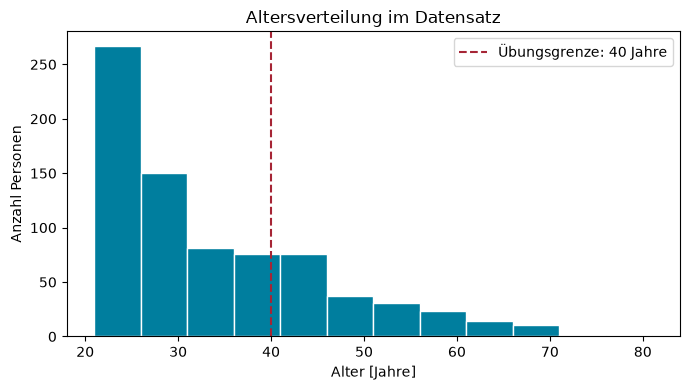

In [12]:
plt.figure(figsize=(7, 4))
plt.hist(ages, bins=12, edgecolor="white", color="#007E9E")
plt.axvline(40, color="#A62535", linestyle="--", label="Übungsgrenze: 40 Jahre")
plt.xlabel("Alter [Jahre]")
plt.ylabel("Anzahl Personen")
plt.title("Altersverteilung im Datensatz")
plt.legend()
plt.tight_layout()
plt.show()

Im Histogramm liegen viele Werte im jüngeren Altersbereich; hohe Alterswerte kommen seltener vor. Der Mittelwert von 33,24 Jahren und der Anteil von 26,95 % ab 40 beschreiben verschiedene Eigenschaften derselben Verteilung. Das Histogramm zeigt außerdem, warum ein einzelner Mittelwert nicht die gesamte Verteilung ersetzt.

## Aufgabe 2: Schwangerschaftsanzahl untersuchen – eigene Bearbeitung

Jetzt untersuchst du die Spalte `Pregnancies`. Sie enthält die dokumentierte Anzahl der Schwangerschaften. Wir berechnen den Mittelwert und den Anteil der Personen mit **weniger als drei** dokumentierten Schwangerschaften.

Der Ablauf orientiert sich an Aufgabe 1. Die folgenden Teilaufgaben bauen aufeinander auf; ergänze und führe sie der Reihe nach aus. Offene Platzhalter müssen noch kein sinnvolles Ergebnis liefern. Vor dem Korrigieren können deshalb auch Fehlermeldungen auftreten.

### a) Python-Grundlagen übertragen

Lege die Liste `pregnancies_small` mit den fünf Werten `[6, 1, 8, 1, 0]` an. Gib den **zweiten** Eintrag aus und berechne den Mittelwert mit `sum` und `len`. Prüfe außerdem, ob der erste Wert kleiner als 3 ist.

In [13]:
pregnancies_small = [6, 1, 8, 1, 0] # Hier dein Code
second_value = pregnancies_small[1] # Hier dein Code
mean_small = sum(pregnancies_small) / len(pregnancies_small) # Hier dein Code
first_is_below_3 = (pregnancies_small[0] < 3)  # Hier dein Code

print("Zweiter Wert:", second_value)
print("Mittelwert:", mean_small)
print("Erster Wert kleiner als 3:", first_is_below_3)

Zweiter Wert: 1
Mittelwert: 3.2
Erster Wert kleiner als 3: False


Welchen Datentyp hat das Ergebnis des Vergleichs mit 3?

Ihre Lösung: Boolean

### b) Einen fehlerhaften Spaltenzugriff debuggen

Die folgende vorbereitete führt Zeile zu einem Fehler. Führe sie einmal aus und lies die Fehlermeldung. Ermittle, wo der Fehler liegt. Korrigiere dann **in derselben Codezelle** den Zugriff und führe sie erneut aus. Am Ende soll `pregnancies` ein eindimensionales Array sein.

In [14]:

df_columns = list(df.columns)
print("Tatsächlich vorhandene Spalten:", df_columns)
pregnancies = df["Pregnancies"].to_numpy() # Hier dein Code
print("Erste fünf Werte:", pregnancies[:5])
print("Anzahl:", len(pregnancies))

Tatsächlich vorhandene Spalten: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
Erste fünf Werte: [6 1 8 1 0]
Anzahl: 768


Notiere den Fehlertyp, die konkrete Ursache und deine Korrektur. Wie würde sich dein erster Prüfschritt ändern, wenn bereits `pd.read_csv(...)` einen `FileNotFoundError` ausgibt?

Ihre Lösung:
Fehler 1: KeyError "pregancies"; Korrektion: "Pregnancies"

Fehler 2: Falscher Funktionaufruf : "too_numpy()" ; korrektion: "to_numpy()"

Der eingegebener Pfad prüfen, ob es den Datein-pfad entspricht.


### c) Eine Dokumentation gezielt verwenden

Verwende die [Dokumentation von `numpy.mean`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) oder `help(np.mean)` aus Aufgabe 1, um den Mittelwert von `pregnancies` zu bestimmen. Runde die Ausgabe auf zwei Nachkommastellen.

Lies außerdem in der [Dokumentation von `matplotlib.pyplot.hist`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) die Beschreibung von `bins`. Beschränke dich zunächst auf diesen Parameter; du musst nicht die gesamte Seite lesen. Im späteren Plot ist die Einstellung bereits vorbereitet.

In [15]:
#help(np.mean)
print("Anzahl:", len(pregnancies))
print("sum:", sum(pregnancies))
mean_pregnancies = round(float(np.mean(pregnancies)), 2) # Hier dein Code
print("Mittlere Schwangerschaftsanzahl:", mean_pregnancies) # Hier dein Code

Anzahl: 768
sum: 2953
Mittlere Schwangerschaftsanzahl: 3.85


Welche Eingabe erwartet der Parameter `a` von `np.mean`, und welcher Wert wird für unsere eindimensionale Folge zurückgegeben? Was ist bei `plt.hist` der Unterschied zwischen einer ganzen Zahl als `bins` und einer Folge von Intervallgrenzen?

Ihre Lösung:

-> a = pregnancies

-> 2953

->Der Unterschied liegt darin, ob du nur die Anzahl der Intervalle angibst oder ihre Grenzen selbst festlegst.

Zum Beispiel: bins=5 erzeugt 5 gleich breite Intervalls automatisch

und bins=[0, 10, 15, 25] erzeugt 4 Intervalle mit exakt diesen Grenzen

### d) Eine Dokumentation lesen und eine Funktion ergänzen

Ergänze `percentage_below(values, threshold)` nach dem Muster der Vorführung. Orientiere dich dafür an der gegebenen Dokumentation. Die Eingabeparameter und die Ausgabe sind im Docstring bereits genau beschrieben.

**Tipp:** Du kannst die passenden Werte mit einer `for`-Schleife und einer `if`-Bedingung zählen. Berechne daraus den Prozentwert und gib ihn zurück.

In [16]:
def percentage_below(values, threshold):
    """Return the percentage of values strictly below a threshold.

    Parameters
    ----------
    values : list of numbers or numpy.ndarray of shape (n_values,)
        Non-empty, one-dimensional sequence of finite numeric values.
    threshold : int or float
        Exclusive upper bound, expressed in the same unit as values.

    Returns
    -------
    percentage : float
        Percentage of entries satisfying value < threshold, from 0 to 100.
    """
    count = 0
    # Hier dein Code
    for value in values:
      if value < threshold:
        count = count +1
    percentage = (count *100) / len(values) # Hier dein Code
    return percentage

Prüfe deine Funktion mit der folgenden vorbereiteten Zelle. Falls du den Funktionscode oder den Docstring änderst, führe zuerst die Definitionszelle erneut aus.

In [17]:
print("Prüfbeispiel, erwartet 50.0 %:", percentage_below([0, 1, 3, 4], 3))

pregnancy_percentage = percentage_below(pregnancies, 3)
print("Anteil mit weniger als drei Schwangerschaften:", round(pregnancy_percentage, 2), "%")

Prüfbeispiel, erwartet 50.0 %: 50.0
Anteil mit weniger als drei Schwangerschaften: 45.44 %


### e) Ergebnisse darstellen und einordnen

Ergänze den Histogrammaufruf für `pregnancies`. Verwende dafür die vorbereiteten Intervallgrenzen `bin_edges` und `edgecolor="white"`. `np.arange(-0.5, 18.5, 1)` erzeugt Werte ab -0,5 in Schritten von 1, wobei die rechte Grenze 18,5 ausgeschlossen bleibt. Die Balken liegen dadurch genau auf den ganzzahligen Schwangerschaftsanzahlen. Achsen, Titel und weitere Formatierung sind vorgegeben.

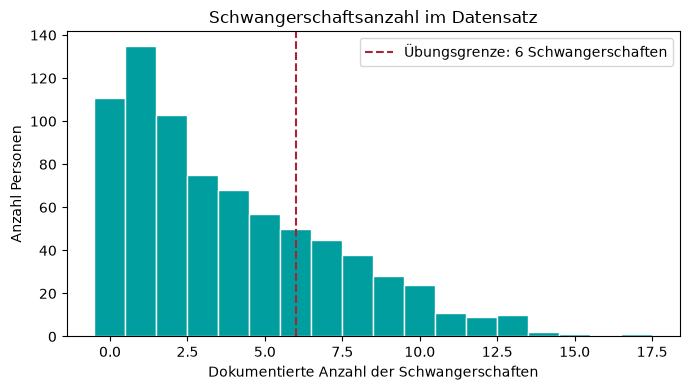

In [18]:
bin_edges = np.arange(-0.5, 18.5, 1)
plt.figure(figsize=(7, 4))
# Hier dein Code: plot the histogram using the prepared bin edges.
plt.hist(pregnancies, bins = bin_edges, color = "#009E9E", edgecolor = "white")
plt.axvline(6, color="#A62535", linestyle="--", label="Übungsgrenze: 6 Schwangerschaften")
plt.legend()
#plt.xticks(range(0, 18, 2))
plt.xlabel("Dokumentierte Anzahl der Schwangerschaften")
plt.ylabel("Anzahl Personen")
plt.title("Schwangerschaftsanzahl im Datensatz")
plt.tight_layout()
plt.show()

In [20]:
import pandas as pd
import sklearn
df = pd.read_csv("C:\\Users\\steve\\Desktop\\Master\\Semester_2\\KI_in_Med\\Übungen\\KI-in-der-Medizin\\src\\Daten\\diabetes.csv")
#df.describe()
#df.info()
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
763    False
764    False
765    False
766    False
767    False
Length: 768, dtype: bool

In [21]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


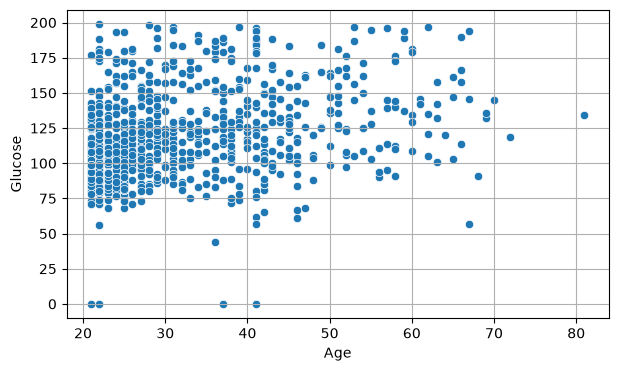

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="Age", y="Glucose")
plt.grid(True)
plt.show()

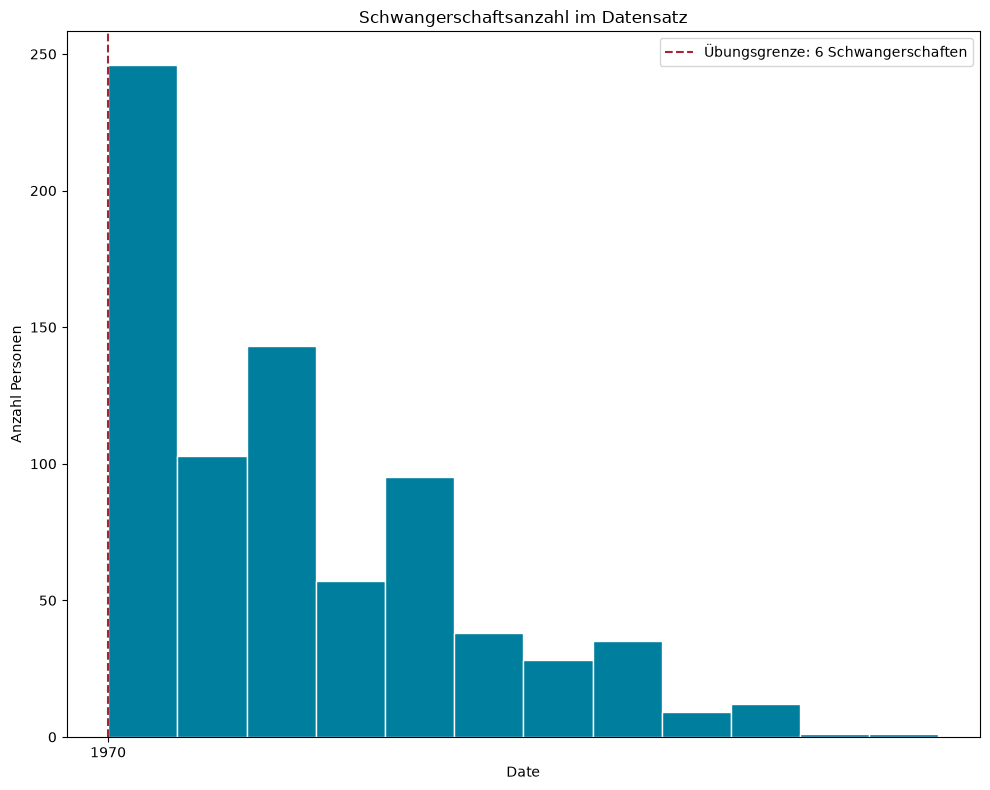

In [23]:
#Plot pregnancie als Datatime
pregnancies_dt = pd.to_datetime(pregnancies)
plt.figure(figsize=(10,8))
plt.hist(pregnancies_dt, bins=12, edgecolor="white", color="#007E9E")
plt.axvline(pd.to_datetime(10), color="#A62535", linestyle="--", label="Übungsgrenze: 6 Schwangerschaften")
plt.xlabel("Date")
plt.ylabel("Anzahl Personen")
plt.title("Schwangerschaftsanzahl im Datensatz")
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\steve\AppData\Local\Temp\ipykernel_22212\2198736395.py:2: RuntimeWarning: divide by zero encountered in divide
  func= lambda x: 1/x


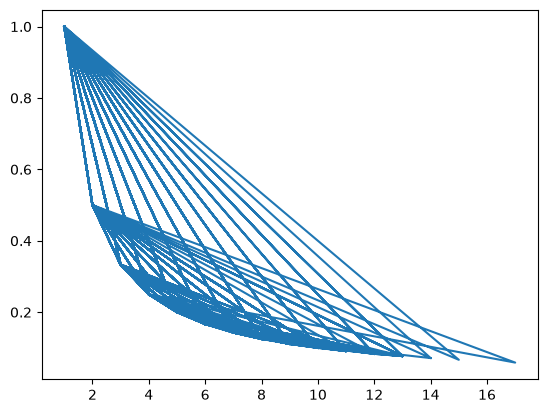

In [24]:
#Berechne eine Regresion function
func= lambda x: 1/x
np.polyfit(pregnancies, pregnancies, 1)
plt.Circle([4,5], 2)
plt.plot(figsize=(18,8))
plt.plot(pregnancies, func(pregnancies))
plt.show()

### Die eigene Bearbeitung abschließen

Speichere deine Änderungen. Starte anschließend die Laufzeit neu und führe dein ergänztes Notebook von oben nach unten aus. Falls die Colab-Dateien dabei nicht mehr vorhanden sind, lade `diabetes.csv` erneut hoch. So merkst du, ob dein Code noch von früher ausgeführten, inzwischen geänderten Zellen abhängt. Vergleiche deine Ergebnisse anschließend mit der Musterlösung und begründe Unterschiede anhand von Code, Daten und Dokumentation.

Für die Weiterarbeit sind diese Seiten hilfreich:

- [Python-Tutorial](https://docs.python.org/3/tutorial/) für Aufbau und Syntax; es eignet sich besonders als Nachschlagewerk nach den ersten Beispielen.
- [Python-Module und Imports](https://docs.python.org/3/tutorial/modules.html) und [Fehler und Ausnahmen](https://docs.python.org/3/tutorial/errors.html).
- [`pandas.read_csv`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) und [Auswahl von Zeilen und Spalten](https://pandas.pydata.org/docs/user_guide/indexing.html).
- [Colab-Informationen](https://research.google.com/colaboratory/faq.html) und die Video- und Textanleitung im Moodle-Kurs.